In [1]:
import jax
print(jax.devices())

[CudaDevice(id=0)]


In [2]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True)   # climate work needs double precision
# Running on Colab? First run:  %pip install -q optax equinox diffrax

In [3]:
S0 = 1361.0       # solar constant, W m^-2
sigma = 5.67e-8   # Stefan-Boltzmann constant, W m^-2 K^-4

def equilibrium_temperature(albedo, emissivity=0.61):
    """Global-mean surface temperature (K) in radiative equilibrium."""
    return (S0 * (1.0 - albedo) / (4.0 * emissivity * sigma)) ** 0.25

T = equilibrium_temperature(0.30)
dT_dalbedo = jax.grad(equilibrium_temperature)(0.30)
print(f"T_eq = {T:.1f} K")
print(f"dT/d(albedo) = {dT_dalbedo:.1f} K per unit albedo")

T_eq = 288.1 K
dT/d(albedo) = -102.9 K per unit albedo


In [5]:
analytic = -T / (4.0 * (1.0 - 0.30))
print(f"autodiff: {dT_dalbedo:.10f}")
print(f"analytic: {analytic:.10f}")

autodiff: -102.8816186994
analytic: -102.8816186994


In [6]:
def finite_difference(f, x, h):
    return (f(x + h) - f(x - h)) / (2.0 * h)

print(" h          FD estimate      |FD - autodiff|")
for h in [1e-2, 1e-4, 1e-6, 1e-8, 1e-10]:
    fd = finite_difference(equilibrium_temperature, 0.30, h)
    print(f"{h:8.0e}   {fd:14.8f}   {abs(fd - dT_dalbedo):.2e}")

 h          FD estimate      |FD - autodiff|
   1e-02    -102.88621211   4.59e-03
   1e-04    -102.88161916   4.59e-07
   1e-06    -102.88161869   1.19e-08
   1e-08    -102.88162002   1.32e-06
   1e-10    -102.88147223   1.46e-04


In [7]:
# forward mode: effect on T of an albedo perturbation of +0.01
_, dT = jax.jvp(equilibrium_temperature, (0.30,), (0.01,))
print(f"tangent linear: dT = {dT:.3f} K for d(albedo) = +0.01")

# reverse mode: sensitivity of T to the input, from one backward pass
T_value, backward = jax.vjp(equilibrium_temperature, 0.30)
(sens,) = backward(1.0)          # propagate dT = 1 back to the input
print(f"adjoint: dT/d(albedo) = {sens:.1f} K")

tangent linear: dT = -1.029 K for d(albedo) = +0.01
adjoint: dT/d(albedo) = -102.9 K


In [9]:
import time

key = jax.random.key(0)
M = jax.random.normal(key, (1000, 1000)) / 1000.0

def scalar_diagnostic(v):                     # many inputs -> one output
    return jnp.sum(jnp.tanh(M @ v) ** 2)

v = jnp.ones(1000)
rev = jax.jit(jax.grad(scalar_diagnostic))    # reverse mode: one backward pass
fwd = jax.jit(jax.jacfwd(scalar_diagnostic))  # forward mode: one pass per input

rev(v).block_until_ready(); fwd(v).block_until_ready()   # compile both
t = time.perf_counter(); rev(v).block_until_ready()
t_rev = time.perf_counter() - t
t = time.perf_counter(); fwd(v).block_until_ready()
t_fwd = time.perf_counter() - t
print(f"reverse mode: {t_rev*1000:7.1f} ms")
print(f"forward mode: {t_fwd*1000:7.1f} ms   ({t_fwd/t_rev:.0f}x slower for 1000 inputs)")
print(f"same result: {bool(jnp.allclose(rev(v), fwd(v)))}")

reverse mode:     0.6 ms
forward mode:     9.6 ms   (15x slower for 1000 inputs)
same result: True


In [10]:
from importlib.resources import files

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from jcm.model import Model as SpeedyModel
from jcm.forcing import ForcingData
from jcm.terrain import TerrainData
from jcm import load_states_from_xarray
from jcm.physics.speedy.speedy_coords import get_speedy_coords
from jcm.physics.speedy.params import Parameters
from jcm.physics.speedy.speedy_terms import speedy_physics

import warnings
warnings.filterwarnings("ignore")

In [11]:
# Spectral T31 grid with 8 vertical levels
coords = get_speedy_coords(spectral_truncation=31, layers=8)

# Load the terrain and climatological boundary forcing shipped with jcm
data = files("jcm") / "data/bc/t30/clim"
terrain = TerrainData.from_file(data / "terrain.nc", coords=coords)
bc = ForcingData.from_file(data / "forcing.nc", coords=coords, align_mode="wrap_year")

print("Terrain variables: ", terrain.asdict().keys())
print("Boundary variables: ", bc.asdict().keys())

Terrain variables:  dict_keys(['orog', 'phis0', 'fmask', 'lfluxland', 'orostd', 'orosig', 'orogam', 'orothe', 'oropic', 'oroval'])
Boundary variables:  dict_keys(['alb0', 'sice_am', 'snowc_am', 'soilw_am', 'stl_am', 'sea_surface_temperature', 'co2_vmr', 'ch4_vmr', 'n2o_vmr', 'aerosol_year_weight', 'aerosol_ann_cycle', 'solar', 'ozone_climatology', 'nudging_target', 'soilw_rel', 'forest_fraction', 'glacier_fraction', 'dms_seawater', 'dust_source', 'dust_preferential', 'dust_soil_types', 'dust_regions', 'dust_roughness', 'oxidant_vmr', 'anthropogenic_emissions', 'prescribed_aerosol_emissions', 'prescribed_sensible_heat_flux', 'prescribed_evaporation', 'prescribed_stress_u', 'prescribed_stress_v', 'prescribed_flux_time_bounds', 'ocean_u', 'ocean_v'])


In [12]:
# Initialize model
model = SpeedyModel(
    coords = coords,
    terrain = terrain, # init terrain (e.g., orography, land mask, etc)
    time_step = 30 # model timestep in minutes
)

In [13]:
# Run model
result = model.run(
    forcing = bc, 
    total_time = 7, # total model integration time in days
    save_interval = 0.5 # save snapshot in days
)

ds = result.to_xarray()

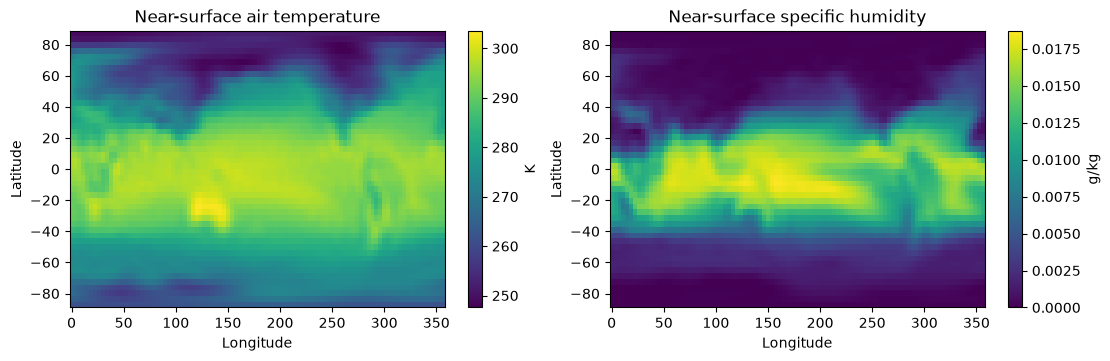

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)

# Plot near-surface T at final timestep
ds.temperature.isel(time=-1, level=0).plot(ax=axes[0], x="lon", y="lat", cmap="viridis", cbar_kwargs={"label": "K"})
axes[0].set(title="Near-surface air temperature", xlabel="Longitude", ylabel="Latitude")

# Plot near-surface q at final timestep
ds.specific_humidity.isel(time=-1, level=0).plot(ax=axes[1], x="lon", y="lat", cmap="viridis", cbar_kwargs={"label": "g/kg"})
axes[1].set(title="Near-surface specific humidity", xlabel="Longitude", ylabel="Latitude");

In [15]:
# Soil moisture availability: (day of year, longitude, latitude)
bc.soilw_am.values.shape

(365, 96, 48)

In [16]:
# Halving soil moisture 
dry_bc = bc.copy(
    soilw_am=bc.soilw_am.replace(values=0.5 * bc.soilw_am.values)
)

In [17]:
# Run
dry = model.run(
    forcing = dry_bc, 
    total_time = 7, 
    save_interval = 0.5
)

dry_ds = dry.to_xarray()

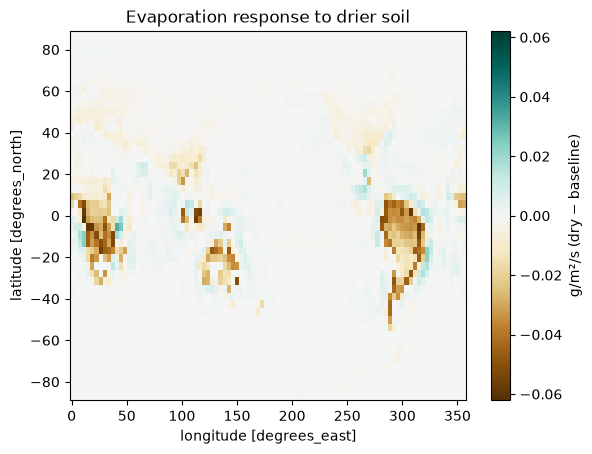

In [19]:
# Plot evaporation response to drier soil
(dry_ds["surface_flux.evap"] - ds["surface_flux.evap"]).isel(time=-1).plot(
    x="lon", y="lat", cmap="BrBG", center=0,
    cbar_kwargs={"label": "g/m²/s (dry − baseline)"}
)
plt.title("Evaporation response to drier soil");

In [22]:
def evaporation(soil_scale):
    forcing = bc.copy(soilw_am=bc.soilw_am.replace(values=soil_scale * bc.soilw_am.values))
    model = SpeedyModel(coords=coords, terrain=terrain, time_step=30)
    result = model.run(forcing=forcing, total_time=0.25, save_interval=0.25) # six-hour run
    ds = result.to_xarray()
    return ds["surface_flux.evap"].isel(time=-1).data

In [23]:
# Start at the original BC; calculate the response to 1% drying.
_, soil_sensitivity = jax.jvp(evaporation, (1.0,), (-0.01,))

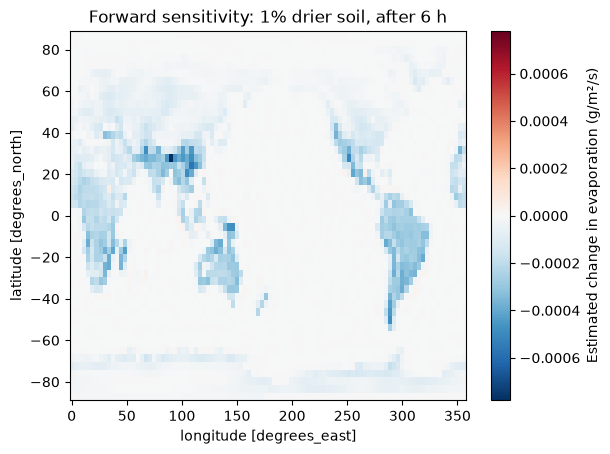

In [25]:
# Plot
soil_map = ds["surface_flux.evap"].isel(time=-1).copy(data=np.asarray(soil_sensitivity))
soil_map.plot(
    x="lon", y="lat", cmap="RdBu_r", center=0,
    cbar_kwargs={"label": "Estimated change in evaporation (g/m²/s)"},
)
plt.title("Forward sensitivity: 1% drier soil, after 6 h");

In [34]:
# Warming IC
ic = load_states_from_xarray(ds.isel(time=-1).sortby("level"))
warmer_ic = ic.copy(temperature=ic.temperature + 4.0)

In [35]:
# Matched control from the same snapshot
ic_control = model.run(
    initial_state = ic, 
    forcing = bc, 
    total_time = 7, 
    save_interval = 0.5
)
control_ds = ic_control.to_xarray()

# Run perturbed model
ic_result = model.run(
    initial_state = warmer_ic, 
    forcing = bc, 
    total_time = 7, 
    save_interval = 0.5
)

ic_ds = ic_result.to_xarray()

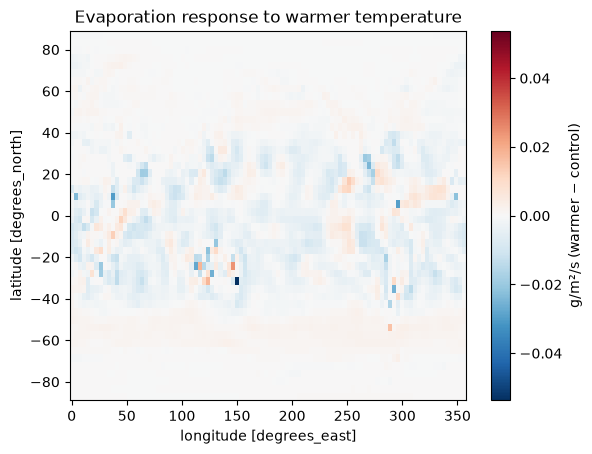

In [37]:
# Plot evaporation response to warmer atmosphere
(ic_ds["surface_flux.evap"] - control_ds["surface_flux.evap"]).isel(time=-1).plot(
    x="lon", y="lat", cmap="RdBu_r", center=0,
    cbar_kwargs={"label": "g/m²/s (warmer − control)"}
)
plt.title("Evaporation response to warmer temperature");

In [38]:
parameters = Parameters.default()
defaults = parameters.surface_flux
land = np.asarray(terrain.fmask) > 0

In [39]:
# Define J (mean land evaporation)
def J(chl, cdl, vgust, fstab, clambda):
    surface = defaults.replace(chl=chl, cdl=cdl, vgust=vgust, fstab=fstab, clambda=clambda)
    physics = speedy_physics(parameters.replace(surface_flux=surface))
    model = SpeedyModel(coords=coords, terrain=terrain, physics=physics, time_step=30)
    result = model.run(initial_state=ic, forcing=bc, total_time=0.25, save_interval=0.25)
    ds = result.to_xarray()
    return ds["surface_flux.evap"].isel(time=-1).data[land].mean()

In [40]:
# Reverse sensitivity at the default parameter values
J0, reverse = jax.vjp(
    J, defaults.chl, defaults.cdl, defaults.vgust, defaults.fstab, defaults.clambda
)
parameter_sensitivity = jnp.array(reverse(1.0)) # starts from dJ/dJ = 1.0 --> dJ/d(theta)
names = ["chl", "cdl", "vgust", "fstab", "clambda"]
units = ["dimensionless unit", "dimensionless unit", "(m/s)", "dimensionless unit", "(W/m²/K)"]
for name, value, unit in zip(names, parameter_sensitivity, units):
    print(f"dJ/d{name:<7} = {value: .3g} g/m²/s per {unit}")

dJ/dchl     =  1.7 g/m²/s per dimensionless unit
dJ/dcdl     = -0.116 g/m²/s per dimensionless unit
dJ/dvgust   =  0.000725 g/m²/s per (m/s)
dJ/dfstab   = -0.00161 g/m²/s per dimensionless unit
dJ/dclambda =  9.29e-06 g/m²/s per (W/m²/K)


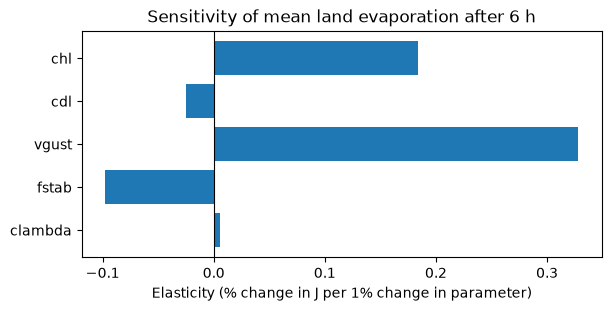

In [41]:
theta = jnp.array([defaults.chl, defaults.cdl, defaults.vgust, defaults.fstab, defaults.clambda])
elasticity = theta / J0 * parameter_sensitivity

fig, ax = plt.subplots(figsize=(6, 3), constrained_layout=True)
ax.barh(names, np.asarray(elasticity))
ax.axvline(0, color="k", lw=0.8)
ax.invert_yaxis()
ax.set(xlabel="Elasticity (% change in J per 1% change in parameter)",
       title="Sensitivity of mean land evaporation after 6 h");